<a href="https://colab.research.google.com/github/sebastianvettel1212/GrokkingDeepLearning/blob/main/12_Neural_Networks_That_Write_Like_Shakespeare_RNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Bab 12 — Neural Networks That Write Like Shakespeare: Recurrent Layers for Variable-Length Data

**Grokking Deep Learning** (Andrew W. Trask) — Tugas 2: *Code Reproduction + Theoretical Deep-Dive*

Bab 11 menangani teks dengan menjumlahkan embedding kata, tetapi cara itu **membuang urutan kata**. Bab ini memperkenalkan *recurrent neural network* (RNN) yang memproses deret berpanjang sembarang sambil mempertahankan urutan.

**Isi notebook:**
1. Tantangan panjang sembarang dan mengapa urutan penting
2. Kekuatan (dan batas) rata-rata vektor kata
3. Matriks identitas → matriks transisi yang dipelajari
4. *Forward propagation* "red sox defeat → yankees" (kode buku)
5. Data bAbI dan model bahasa RNN: forward, backprop, dan update bobot dengan panjang sembarang
6. Analisis output (*perplexity*, prediksi kata berikutnya)
7. Tanya-jawab konsep, latihan mandiri, dan rangkuman

> **Catatan data:** buku memakai dataset **bAbI** (cerita pendek, mis. *Mary moved to the bathroom*). `load_babi()` mencoba mengunduh data asli dan, bila gagal, memakai **cerita sintetis bergaya bAbI** agar notebook tetap berjalan offline. Sumber data aktual dicetak pada output sel pemuatan data.

## 1. Mengapa urutan penting: batas *bag of words*

In [1]:
import numpy as np, sys, urllib.request, io, tarfile
from collections import Counter
import matplotlib.pyplot as plt
np.random.seed(1)

def softmax(x_):
    x = np.atleast_2d(x_)
    temp = np.exp(x - np.max(x, axis=1, keepdims=True))
    return temp / np.sum(temp, axis=1, keepdims=True)

# Tambahan: dua kalimat berbeda arti tetapi kata-katanya sama
vocab_demo = ["red","sox","defeat","yankees","blue"]
emb = {w: np.random.randn(4) for w in vocab_demo}
a = ["red","sox","defeat","yankees"]; b = ["yankees","defeat","sox","red"]
sum_a = sum(emb[w] for w in a); sum_b = sum(emb[w] for w in b)
print("Jumlah embedding 'red sox defeat yankees' == 'yankees defeat sox red' ?", np.allclose(sum_a, sum_b))

Jumlah embedding 'red sox defeat yankees' == 'yankees defeat sox red' ? True


Penjumlahan bersifat komutatif, sehingga kedua kalimat di atas memiliki vektor kalimat **identik**. Kalimat dengan arti berlawanan tidak akan bisa dibedakan. Solusi buku: sebelum menambahkan embedding kata berikutnya, vektor kalimat sebelumnya dikalikan sebuah **matriks transisi**. Jika matriks itu identitas, hasilnya sama dengan penjumlahan biasa; jika matriks itu *dipelajari*, urutan menjadi bermakna.

In [2]:
# Menjumlahkan embedding dengan matriks identitas = penjumlahan biasa
I = np.eye(4)
h = np.zeros(4)
for w in a: h = h.dot(I) + emb[w]
print("Identitas sama dengan penjumlahan biasa:", np.allclose(h, sum_a))

# Matriks transisi bukan identitas -> urutan berpengaruh
R = np.random.randn(4, 4) * 0.5
def run(sent, R):
    h = np.zeros(4)
    for w in sent: h = h.dot(R) + emb[w]
    return h
print("Dengan matriks transisi acak, dua urutan sama?:", np.allclose(run(a, R), run(b, R)))
print("Jarak antar vektor kalimat:", np.linalg.norm(run(a, R) - run(b, R)).round(3))

Identitas sama dengan penjumlahan biasa: True
Dengan matriks transisi acak, dua urutan sama?: False
Jarak antar vektor kalimat: 2.486


## 2. *Forward propagation* "red sox defeat" → "yankees" (kode buku)

Kosakata mini sembilan kata, embedding awal nol, matriks transisi identitas, dan lapisan `sent2output` untuk memprediksi kata berikutnya. Karena semua embedding 0, prediksi awal seragam (1/9).

In [3]:
word_vects = {}
for w in ['yankees','bears','braves','red','sox','lose','defeat','beat','tie']:
    word_vects[w] = np.array([[0.,0.,0.]])
sent2output = np.random.rand(3, len(word_vects))
identity = np.eye(3)

layer_0 = word_vects['red']
layer_1 = layer_0.dot(identity) + word_vects['sox']
layer_2 = layer_1.dot(identity) + word_vects['defeat']
pred = softmax(layer_2.dot(sent2output))
print(np.round(pred, 4))

[[0.1111 0.1111 0.1111 0.1111 0.1111 0.1111 0.1111 0.1111 0.1111]]


### Memuat data bAbI

Setiap baris cerita bAbI berupa kalimat pendek tentang orang yang berpindah tempat. Model bahasa akan belajar **memprediksi kata berikutnya** pada setiap posisi.

In [4]:
def synthetic_babi(n=1500, seed=0):
    rng = np.random.RandomState(seed)
    names = ["mary","john","sandra","daniel"]
    verbs = ["moved","went","journeyed","travelled"]
    places = ["bathroom","hallway","garden","kitchen","office","bedroom"]
    return [[names[rng.randint(4)], verbs[rng.randint(4)], "to", "the", places[rng.randint(6)]] for _ in range(n)]

def load_babi():
    url = "http://www.thespermwhale.com/jaseweston/babi/tasks_1-20_v1-2.tar.gz"
    try:
        data = urllib.request.urlopen(url, timeout=8).read()
        tf = tarfile.open(fileobj=io.BytesIO(data), mode="r:gz")
        name = [m for m in tf.getnames() if m.endswith("en/qa1_single-supporting-fact_train.txt")][0]
        raw = tf.extractfile(name).read().decode().splitlines()
        toks = []
        for line in raw:
            if "?" in line: continue
            parts = line.lower().replace(".", "").split(" ")[1:]
            if parts: toks.append(parts)
        return toks, "bAbI asli (qa1_single-supporting-fact)"
    except Exception:
        return synthetic_babi(), "SINTETIS bergaya bAbI (unduhan gagal / offline)"

tokens, source = load_babi()
print("Sumber data:", source, "| jumlah kalimat:", len(tokens))
print("Contoh kalimat:", tokens[0], "|", tokens[1])

wordcnt = Counter()
for sent in tokens:
    for word in sent: wordcnt[word] -= 1
vocab = [w for w, _ in sorted(wordcnt.items(), key=lambda x: x[1])]
word2index = {w: i for i, w in enumerate(vocab)}

def words2indices(sentence): return [word2index[w] for w in sentence]
print("Ukuran kosakata:", len(vocab))

Sumber data: SINTETIS bergaya bAbI (unduhan gagal / offline) | jumlah kalimat: 1500
Contoh kalimat: ['mary', 'travelled', 'to', 'the', 'bedroom'] | ['mary', 'travelled', 'to', 'the', 'kitchen']
Ukuran kosakata: 16


## 3. RNN model bahasa: *forward propagation* dengan panjang sembarang

`layers` adalah daftar yang bertambah panjang sesuai panjang kalimat. Setiap langkah: (1) memprediksi kata berikutnya dari vektor tersembunyi sebelumnya, (2) menghitung loss, (3) membentuk vektor tersembunyi baru `hidden = hidden·recurrent + embed[kata]`. Matriks `recurrent` dimulai sebagai identitas (pada buku: dimulai identitas lalu dipelajari).

In [5]:
np.random.seed(1)
embed_size = 10
embed = (np.random.rand(len(vocab), embed_size) - 0.5) * 0.1
recurrent = np.eye(embed_size)
start = np.zeros(embed_size)
decoder = (np.random.rand(embed_size, len(vocab)) - 0.5) * 0.1
one_hot = np.eye(len(vocab))

def predict(sent):
    layers = list()
    layer = {}
    layer['hidden'] = start
    layers.append(layer)
    loss = 0
    for target_i in range(len(sent)):
        layer = {}
        layer['pred'] = softmax(layers[-1]['hidden'].dot(decoder))[0]
        loss += -np.log(layer['pred'][sent[target_i]])
        layer['hidden'] = layers[-1]['hidden'].dot(recurrent) + embed[sent[target_i]]
        layers.append(layer)
    return layers, loss

layers, loss = predict(words2indices(tokens[0]))
print("Jumlah layer untuk 1 kalimat (%d kata): %d" % (len(tokens[0]), len(layers)))
print("Loss awal: %.3f | perplexity awal: %.2f (kosakata=%d)" % (loss, np.exp(loss/len(tokens[0])), len(vocab)))

Jumlah layer untuk 1 kalimat (5 kata): 6
Loss awal: 13.872 | perplexity awal: 16.03 (kosakata=16)


## 4. *Backpropagation* dan update bobot untuk panjang sembarang (kode buku)

Gradien dihitung mundur dari layer terakhir. Setiap `hidden_delta` menerima dua sumber: gradien dari prediksi di langkah itu (`output_delta · decoderᵀ`) dan gradien dari langkah berikutnya (`hidden_delta_berikut · recurrentᵀ`). Pembaruan bobot dibagi `len(sent)` agar kalimat panjang tidak mendominasi.

> Catatan: pengindeksan `hidden_delta` pada kode buku sederhana dan tidak sama persis dengan gradien analitik eksak (prediksi pada layer *k* memakai hidden layer *k−1*). Meskipun demikian, hasil pelatihannya tetap menurunkan *perplexity* seperti terlihat di bawah.

In [6]:
perp_hist = []
for it in range(20000):
    alpha = 0.002   # buku: 0.001 (30000 iterasi); 0.002 dipakai agar data kecil cepat konvergen. alpha >= 0.005 membuat pelatihan meledak (NaN)
    sent = words2indices(tokens[it % len(tokens)])
    layers, loss = predict(sent)

    for layer_idx in reversed(range(len(layers))):
        layer = layers[layer_idx]
        target = sent[layer_idx - 1]
        if layer_idx > 0:
            layer['output_delta'] = layer['pred'] - one_hot[target]
            new_hidden_delta = layer['output_delta'].dot(decoder.transpose())
            if layer_idx == len(layers) - 1:
                layer['hidden_delta'] = new_hidden_delta
            else:
                layer['hidden_delta'] = new_hidden_delta + layers[layer_idx+1]['hidden_delta'].dot(recurrent.transpose())
        else:
            layer['hidden_delta'] = layers[layer_idx+1]['hidden_delta'].dot(recurrent.transpose())

    start -= layers[0]['hidden_delta'] * alpha / float(len(sent))
    for layer_idx, layer in enumerate(layers[1:]):
        decoder -= np.outer(layers[layer_idx]['hidden'], layer['output_delta']) * alpha / float(len(sent))
        embed_idx = sent[layer_idx]
        embed[embed_idx] -= layers[layer_idx]['hidden_delta'] * alpha / float(len(sent))
        recurrent -= np.outer(layers[layer_idx]['hidden'], layer['hidden_delta']) * alpha / float(len(sent))

    perp_hist.append(np.exp(loss / len(sent)))
    if it % 2000 == 0:
        print("Iter %5d  Perplexity: %.3f" % (it, np.mean(perp_hist[-200:]) if it else perp_hist[0]))

Iter     0  Perplexity: 16.029
Iter  2000  Perplexity: 15.889
Iter  4000  Perplexity: 12.931
Iter  6000  Perplexity: 11.072
Iter  8000  Perplexity: 5.191
Iter 10000  Perplexity: 4.428
Iter 12000  Perplexity: 3.899
Iter 14000  Perplexity: 3.499
Iter 16000  Perplexity: 3.221
Iter 18000  Perplexity: 2.975


## 5. Analisis output

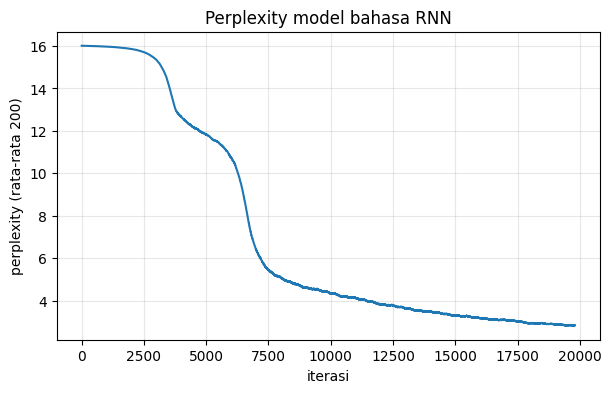

Perplexity akhir (rata-rata 1000 terakhir): 2.862
Perplexity acak (kosakata 16): 16


In [7]:
sm = np.convolve(perp_hist, np.ones(200)/200, mode="valid")
plt.figure(figsize=(7,4)); plt.plot(sm); plt.xlabel("iterasi"); plt.ylabel("perplexity (rata-rata 200)")
plt.title("Perplexity model bahasa RNN"); plt.grid(alpha=.3); plt.show()
print("Perplexity akhir (rata-rata 1000 terakhir): %.3f" % np.mean(perp_hist[-1000:]))
print("Perplexity acak (kosakata %d): %d" % (len(vocab), len(vocab)))

In [8]:
def next_word(prefix, k=4):
    layers, _ = predict(words2indices(prefix))
    h = layers[-1]['hidden']
    p = softmax(h.dot(decoder))[0]
    top = np.argsort(-p)[:k]
    return [(vocab[i], round(float(p[i]), 3)) for i in top]

demo = tokens[0][:3]
print("Konteks:", demo, "->", next_word(demo))
demo = tokens[0][:2] + ["to"] if len(tokens[0]) > 2 else tokens[0][:2]
print("Konteks:", demo, "->", next_word(demo))
print("Awal kalimat (hanya <start>) ->", [(vocab[i], round(float(softmax(start.dot(decoder))[0][i]),3)) for i in np.argsort(-softmax(start.dot(decoder))[0])[:4]])

Konteks: ['mary', 'travelled', 'to'] -> [('the', 0.999), ('bedroom', 0.0), ('kitchen', 0.0), ('hallway', 0.0)]
Konteks: ['mary', 'travelled', 'to'] -> [('the', 0.999), ('bedroom', 0.0), ('kitchen', 0.0), ('hallway', 0.0)]
Awal kalimat (hanya <start>) -> [('daniel', 0.189), ('sandra', 0.188), ('mary', 0.176), ('john', 0.175)]


### Tambahan: apakah `recurrent` masih identitas?

*(Tambahan.)* Matriks transisi dimulai sebagai identitas. Berapa jauh ia berubah setelah pelatihan?

||recurrent - I||_F = 3.2344


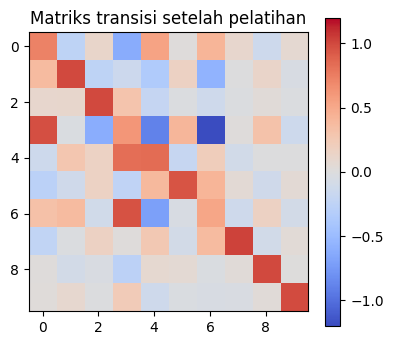

In [9]:
print("||recurrent - I||_F =", round(float(np.linalg.norm(recurrent - np.eye(embed_size))), 4))
plt.figure(figsize=(4.5,4)); plt.imshow(recurrent, cmap="coolwarm", vmin=-1.2, vmax=1.2); plt.colorbar()
plt.title("Matriks transisi setelah pelatihan"); plt.show()

## 6. Tanya-jawab konsep

**1. Mengapa rata-rata/jumlah embedding kata tidak cukup?** Penjumlahan komutatif sehingga urutan hilang: "red sox defeat yankees" dan "yankees defeat sox red" menghasilkan vektor sama (terbukti `True` di atas).

**2. Apa peran matriks identitas dalam RNN buku?** Dengan identitas, `h·I + e = h + e` sama dengan penjumlahan biasa. Ini titik awal; matriks lalu dipelajari sehingga transformasi di antara kata menjadi bermakna.

**3. Mengapa prediksi dilakukan di setiap langkah waktu?** Lebih efisien: satu forward propagation menghasilkan banyak sinyal belajar (satu per kata), tanpa mengulang dari awal kalimat untuk setiap target.

**4. Apa itu perplexity?** `exp(rata-rata loss per kata)`: kira-kira jumlah kata yang "dibingungkan" model pada tiap posisi. Perplexity = ukuran kosakata berarti tebakan acak; semakin rendah semakin baik.

**5. Mengapa gradien dibagi `len(sent)`?** Agar kalimat panjang (yang menghasilkan lebih banyak gradien) tidak mendominasi pembaruan.

**6. Apa tantangan backpropagation pada RNN?** Gradien dijalarkan melewati `recurrent` berulang kali; pada deret panjang gradien dapat mengecil atau meledak (dibahas pada Bab 14).

## 7. Latihan mandiri (dengan jawaban)

**Latihan 1.** Untuk kalimat 5 kata, berapa jumlah `layers`? **Jawaban:** 6 (1 layer awal + 1 per kata).

**Latihan 2.** Apa perplexity model acak pada kosakata 20 kata? **Jawaban:** 20.

**Latihan 3.** Jika `recurrent` diganti `np.zeros`, apa yang terjadi pada forward? **Jawaban:** `hidden` hanya bergantung pada kata terakhir (`embed[kata]`); konteks sebelumnya dihapus.

**Latihan 4.** Mengapa kata pertama diprediksi dari `start`? **Jawaban:** Belum ada konteks, sehingga `start` (dipelajari) mewakili "kalimat kosong".

## Rangkuman

- Penjumlahan embedding membuang urutan; **matriks transisi** yang dipelajari membuat vektor kalimat peka urutan.
- RNN memproses deret berpanjang sembarang dengan menambah layer sesuai panjang input dan memakai **bobot yang sama** di setiap langkah (`recurrent`, `embed`, `decoder`).
- Backprop melewati waktu: `hidden_delta` menerima gradien dari prediksi saat ini dan dari langkah berikutnya.
- Perplexity turun dari ≈ ukuran kosakata (tebakan acak, 16) pada awal pelatihan menjadi ≈ 2,9 pada data sintetis (batas teoretis data ini ≈ 2,5). Learning rate terlalu besar (≥ 0,005) membuat gradien meledak dan loss menjadi NaN, contoh nyata *exploding gradient* (Bab 14).